In [2]:
import nltk
from os import getcwd
import pandas as pd     
from nltk.corpus import twitter_samples
import matplotlib.pyplot as plt
import numpy as np

from utils import process_tweet, build_freqs

nltk.download('twitter_samples')

[nltk_data] Downloading package twitter_samples to
[nltk_data]     /home/heniath/nltk_data...
[nltk_data]   Package twitter_samples is already up-to-date!


True

In [ ]:
all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')

tweets = all_positive_tweets + all_negative_tweets
labels = np.append(np.ones((len(all_positive_tweets),1)), np.zeros((len(all_negative_tweets),1)), axis=1)

train_pos = all_positive_tweets[:4000]
train_neg = all_negative_tweets[:4000]

train_x = train_pos + train_neg

print(f'Number of train tweets: {len(train_x)}')

0.0
Number of train tweets: 8000


In [14]:
data = pd.read_csv('./data/logistic_features.csv')
print(data.head())
print(data.tail())

   bias  positive  negative  sentiment
0   1.0    3020.0      61.0        1.0
1   1.0    3573.0     444.0        1.0
2   1.0    3005.0     115.0        1.0
3   1.0    2862.0       4.0        1.0
4   1.0    3119.0     225.0        1.0
      bias  positive  negative  sentiment
7995   1.0      29.0    3706.0        0.0
7996   1.0      62.0     323.0        0.0
7997   1.0     144.0     783.0        0.0
7998   1.0     205.0    3890.0        0.0
7999   1.0     189.0    3974.0        0.0


In [19]:
X = data[['bias', 'positive', 'negative']].to_numpy()
Y = data['sentiment'].to_numpy()

print(X.shape)
print(X)

(8000, 3)
[[1.000e+00 3.020e+03 6.100e+01]
 [1.000e+00 3.573e+03 4.440e+02]
 [1.000e+00 3.005e+03 1.150e+02]
 ...
 [1.000e+00 1.440e+02 7.830e+02]
 [1.000e+00 2.050e+02 3.890e+03]
 [1.000e+00 1.890e+02 3.974e+03]]


In [35]:
theta = [6.03518871e-08, 5.38184972e-04, -5.58300168e-04]

Text(0, 0.5, 'Negative')

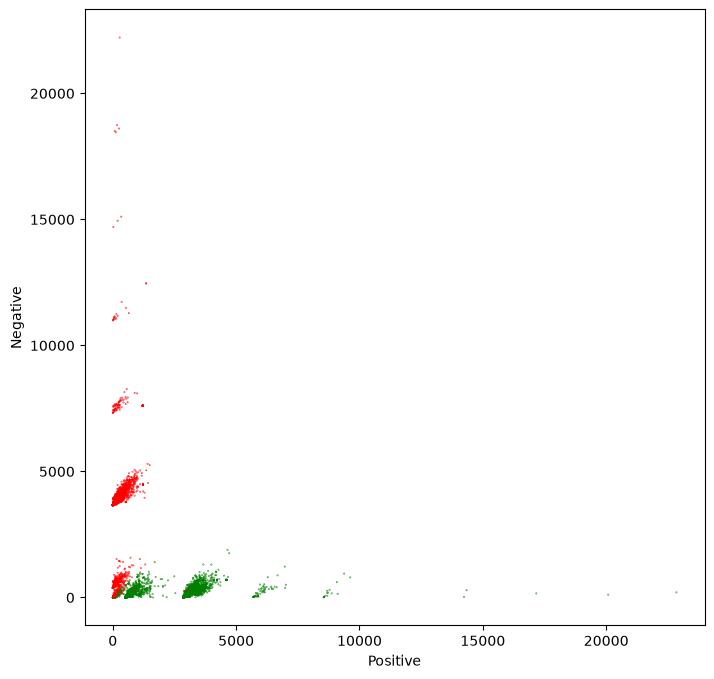

In [25]:
fig, ax = plt.subplots(figsize=(8, 8))

colors = ['red', 'green']

ax.scatter(X[:, 1], X[:, 2], c=[colors[int(k)] for k in Y], s=0.1)
plt.xlabel('Positive')
plt.ylabel('Negative')

In [33]:
def neg(theta, pos):
    return (-theta[0] - pos * theta[1]) / theta[2]

def direction(theta, pos):
    return pos * theta[2] / theta[1]

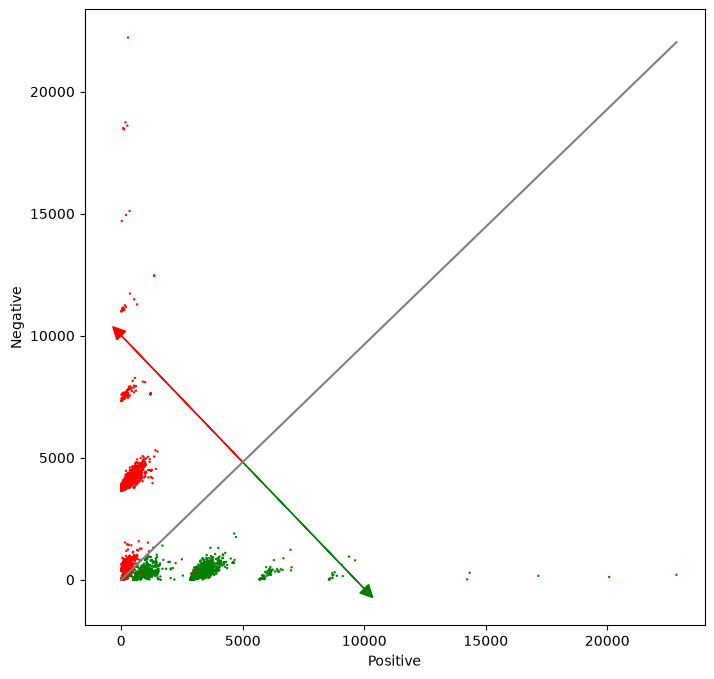

In [41]:
fix, ax = plt.subplots(figsize=(8, 8))

colors = ['red', 'green']

ax.scatter(X[:, 1], X[:, 2], c=[colors[int(k)] for k in Y], s=0.5)
plt.xlabel('Positive')
plt.ylabel('Negative')

max_pos = np.max(X[:, 1])
offset = 5000

ax.plot([0, max_pos], [neg(theta, 0), neg(theta, max_pos)], c='gray')
ax.arrow(offset, neg(theta, offset), offset, direction(theta, offset), head_width=500, head_length=500, fc='g', ec='g')
ax.arrow(offset, neg(theta, offset), -offset, -direction(theta, offset), head_width=500, head_length=500, fc='r', ec='r')

plt.show()